In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn

  Using cached scikit_learn-1.9.0-cp313-cp313-win_amd64.whl.metadata (11 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.25.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.0-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.25.0-py3-none-any.whl (467 kB)
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   - -------------------------------------- 1.6/36.6 MB 10.0 MB/s eta 0:00:04
   ---- ----------------------------------- 4.2/36.6 MB 12.0 MB/s eta 0:00:03
   ------ --------------------------------- 6.3/36.6 MB 12.4 MB/s eta 0:00:03
   ---------- ----------------------------- 9.7/36.6 MB 12.5 MB/s eta 0:00:03
   ----------- ----------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [15]:
# Load dataset
df = pd.read_csv("../data/raw/ObesityDataSet_raw_and_data_sinthetic.csv")

# Display basic information
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (2111, 17)

First 5 Rows:


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   str    
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   str    
 12  FAF                    

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
count,2111.000000,2111,2111.000000,2111.000000,2111,2111,2111.000000,2111.000000,2111,2111,2111.000000,2111,2111.000000,2111.000000,2111,2111,2111
unique,NaN,2,NaN,NaN,4,2,NaN,NaN,2,2,NaN,2,NaN,NaN,4,5,7
top,NaN,Male,NaN,NaN,Sometimes,yes,NaN,NaN,no,no,NaN,yes,NaN,NaN,Sometimes,Public_Transportation,Obesity_Type_I
freq,NaN,1068,NaN,NaN,1401,1866,NaN,NaN,2015,2067,NaN,1726,NaN,NaN,1765,1580,351
mean,24.312600,NaN,1.701677,86.586058,NaN,NaN,2.419043,2.685628,NaN,NaN,2.008011,NaN,1.010298,0.657866,NaN,NaN,NaN
std,6.345968,NaN,0.093305,26.191172,NaN,NaN,0.533927,0.778039,NaN,NaN,0.612953,NaN,0.850592,0.608927,NaN,NaN,NaN
min,14.000000,NaN,1.450000,39.000000,NaN,NaN,1.000000,1.000000,NaN,NaN,1.000000,NaN,0.000000,0.000000,NaN,NaN,NaN
25%,19.947192,NaN,1.630000,65.473343,NaN,NaN,2.000000,2.658738,NaN,NaN,1.584812,NaN,0.124505,0.000000,NaN,NaN,NaN
50%,22.777890,NaN,1.700499,83.000000,NaN,NaN,2.385502,3.000000,NaN,NaN,2.000000,NaN,1.000000,0.625350,NaN,NaN,NaN
75%,26.000000,NaN,1.768464,107.430682,NaN,NaN,3.000000,3.000000,NaN,NaN,2.477420,NaN,1.666678,1.000000,NaN,NaN,NaN


In [16]:
# Target variable
target = "NObeyesdad"

print("Problem Type: Multiclass Classification")
print("Target Variable:", target)

print("\nTarget Classes:")
print(df[target].unique())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate values
print("\nDuplicate Rows:", df.duplicated().sum())

Problem Type: Multiclass Classification
Target Variable: NObeyesdad

Target Classes:
<StringArray>
[      'Normal_Weight',  'Overweight_Level_I', 'Overweight_Level_II',
      'Obesity_Type_I', 'Insufficient_Weight',     'Obesity_Type_II',
    'Obesity_Type_III']
Length: 7, dtype: str

Missing Values:
Age                               0
Gender                            0
Height                            0
Weight                            0
CALC                              0
FAVC                              0
FCVC                              0
NCP                               0
SCC                               0
SMOKE                             0
CH2O                              0
family_history_with_overweight    0
FAF                               0
TUE                               0
CAEC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

Duplicate Rows: 24


In [19]:
# Handle missing values

numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = df.select_dtypes(
    include=["object"]
).columns

# Numerical missing values → median
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Categorical missing values → mode
for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Remove duplicate rows
df = df.drop_duplicates()

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("\nDataset shape after cleaning:", df.shape)

Missing values after cleaning:
0

Dataset shape after cleaning: (2087, 17)


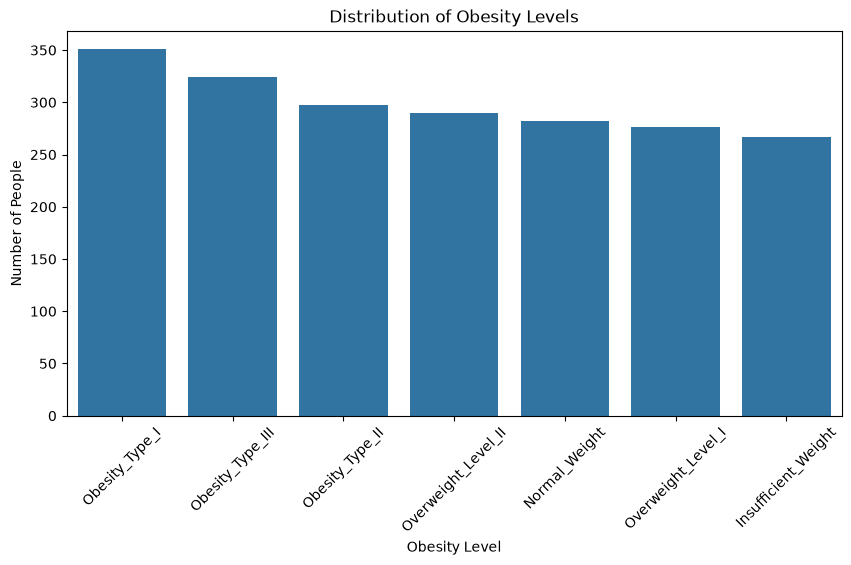

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64


In [20]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="NObeyesdad",
    order=df["NObeyesdad"].value_counts().index
)

plt.title("Distribution of Obesity Levels")
plt.xlabel("Obesity Level")
plt.ylabel("Number of People")
plt.xticks(rotation=45)
plt.show()

print(df["NObeyesdad"].value_counts())

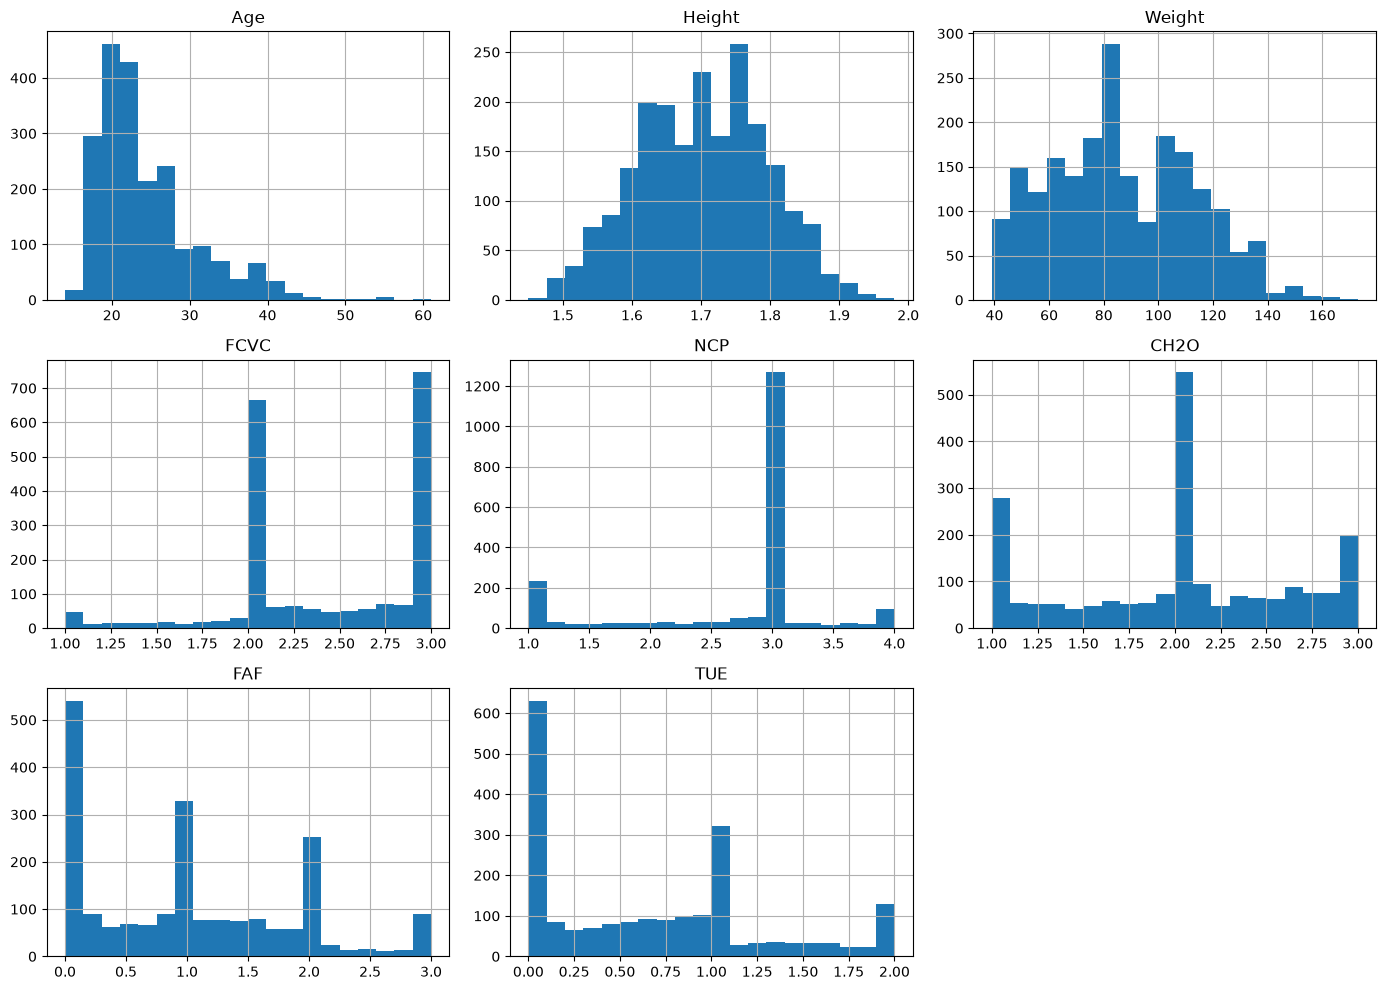

Outlier Count:
Age: 167
Height: 1
Weight: 1
FCVC: 0
NCP: 577
CH2O: 0
FAF: 0
TUE: 0


In [21]:
# Numerical columns
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Histograms
df[numeric_columns].hist(
    figsize=(14, 10),
    bins=20
)

plt.tight_layout()
plt.show()

# Outlier detection using IQR
print("Outlier Count:")

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {count}")

BMI Feature Created Successfully!


,Height,Weight,BMI,NObeyesdad
0,1.62,64.0,24.386526,Normal_Weight
1,1.52,56.0,24.238227,Normal_Weight
2,1.80,77.0,23.765432,Normal_Weight
3,1.80,87.0,26.851852,Overweight_Level_I
4,1.78,89.8,28.342381,Overweight_Level_II


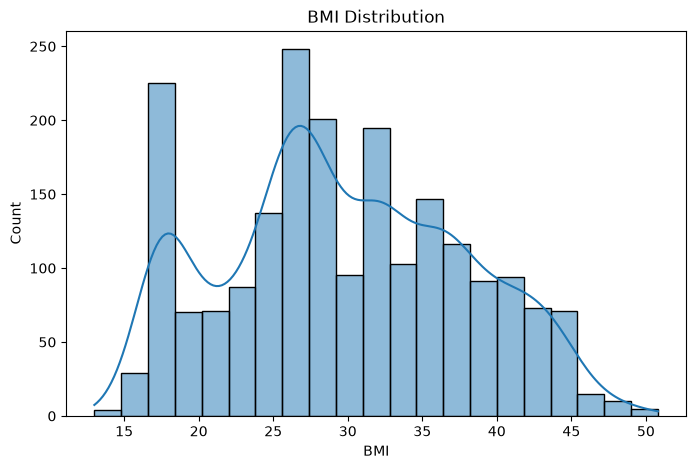

In [22]:
# Calculate BMI
df["BMI"] = df["Weight"] / (df["Height"] ** 2)

print("BMI Feature Created Successfully!")

display(
    df[["Height", "Weight", "BMI", "NObeyesdad"]].head()
)

# BMI distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    df["BMI"],
    kde=True
)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.show()

In [23]:
# Features
X = df.drop("NObeyesdad", axis=1)

# Target
y = df["NObeyesdad"]

# Identify column types
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Numerical Features:
['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE', 'BMI']

Categorical Features:
['Gender', 'CALC', 'FAVC', 'SCC', 'SMOKE', 'family_history_with_overweight', 'CAEC', 'MTRANS']

X Shape: (2087, 17)
y Shape: (2087,)


In [24]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1669, 17)
Testing Data: (418, 17)


In [25]:
# Model 1: Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Model 2: Decision Tree
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Model 3: Random Forest
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

# Model 4: KNN
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "KNN": knn_model
}

# Train all models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully
KNN trained successfully


,Model,Accuracy
2,Random Forest,0.973684
1,Decision Tree,0.968900
0,Logistic Regression,0.925837
3,KNN,0.863636


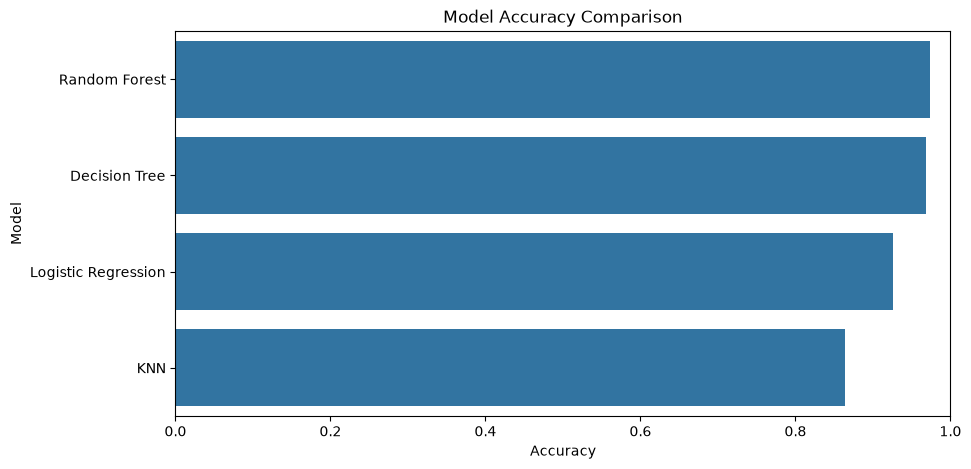

In [26]:
results = []

predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    predictions[name] = y_pred

# Results table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

display(results_df)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.xlim(0, 1)
plt.title("Model Accuracy Comparison")
plt.show()

In [27]:
# Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            random_state=42
        )
    )
])

# Parameters to test
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5]
}

# Grid Search with 5-fold cross validation
grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best Cross Validation Accuracy:
0.9808347269425113


Tuned Random Forest Accuracy: 0.9808612440191388

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       1.00      1.00      1.00        53
      Normal_Weight       0.90      1.00      0.95        57
     Obesity_Type_I       1.00      1.00      1.00        70
    Obesity_Type_II       0.98      1.00      0.99        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       1.00      0.91      0.95        55
Overweight_Level_II       0.98      0.97      0.97        58

           accuracy                           0.98       418
          macro avg       0.98      0.98      0.98       418
       weighted avg       0.98      0.98      0.98       418



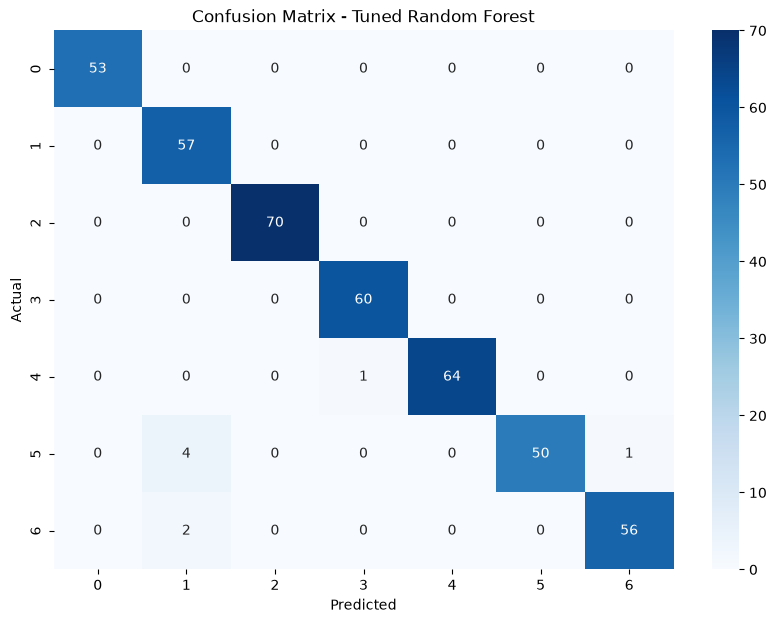

In [28]:
# Predictions from tuned Random Forest
tuned_predictions = grid_search.predict(X_test)

tuned_accuracy = accuracy_score(
    y_test,
    tuned_predictions
)

print("Tuned Random Forest Accuracy:",
      tuned_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        tuned_predictions
    )
)

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    tuned_predictions
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [30]:
# Create new person's data
new_person = pd.DataFrame({
    "Age": [25],
    "Gender": ["Male"],
    "Height": [1.75],
    "Weight": [80],
    "CALC": ["Sometimes"],
    "FAVC": ["yes"],
    "FCVC": [2],
    "NCP": [3],
    "SCC": ["no"],
    "SMOKE": ["no"],
    "CH2O": [2],
    "family_history_with_overweight": ["yes"],
    "FAF": [1],
    "TUE": [1],
    "CAEC": ["Sometimes"],
    "MTRANS": ["Public_Transportation"]
})

# Create BMI because the trained model contains BMI
new_person["BMI"] = (
    new_person["Weight"] /
    (new_person["Height"] ** 2)
)

# Prediction
prediction = grid_search.predict(new_person)

print("New Person Details:")
display(new_person)

print(
    "\nPredicted Obesity Level:",
    prediction[0]
)

New Person Details:


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,BMI
0,25,Male,1.75,80,Sometimes,yes,2,3,no,no,2,yes,1,1,Sometimes,Public_Transportation,26.122449



Predicted Obesity Level: Overweight_Level_I


In [31]:
print("=" * 60)
print("FINAL CONCLUSION")
print("=" * 60)

print("""
1. The ObesityDataSet.csv dataset was successfully loaded
   and analyzed.

2. Missing values and duplicate records were checked
   and handled.

3. Exploratory Data Analysis was performed to understand
   the dataset and obesity-level distribution.

4. BMI was created as a new engineered feature using
   Height and Weight.

5. Four classification models were trained:
   - Logistic Regression
   - Decision Tree
   - Random Forest
   - K-Nearest Neighbors

6. The models were evaluated using accuracy and
   classification reports.

7. Random Forest was further improved using
   GridSearchCV and 5-fold cross-validation.

8. The tuned model was evaluated using a confusion matrix
   and classification report.

9. Finally, the trained model was used to predict the
   obesity level of a new/unseen person.

The final model can be used to predict obesity levels
from physical, eating and lifestyle-related features.
""")

print("\nBest Initial Models:")
display(results_df)

print(
    f"\nTuned Random Forest Accuracy: "
    f"{tuned_accuracy:.2%}"
)

FINAL CONCLUSION

1. The ObesityDataSet.csv dataset was successfully loaded
   and analyzed.

2. Missing values and duplicate records were checked
   and handled.

3. Exploratory Data Analysis was performed to understand
   the dataset and obesity-level distribution.

4. BMI was created as a new engineered feature using
   Height and Weight.

5. Four classification models were trained:
   - Logistic Regression
   - Decision Tree
   - Random Forest
   - K-Nearest Neighbors

6. The models were evaluated using accuracy and
   classification reports.

7. Random Forest was further improved using
   GridSearchCV and 5-fold cross-validation.

8. The tuned model was evaluated using a confusion matrix
   and classification report.

9. Finally, the trained model was used to predict the
   obesity level of a new/unseen person.

The final model can be used to predict obesity levels
from physical, eating and lifestyle-related features.


Best Initial Models:


,Model,Accuracy
2,Random Forest,0.973684
1,Decision Tree,0.968900
0,Logistic Regression,0.925837
3,KNN,0.863636



Tuned Random Forest Accuracy: 98.09%
